# Health Study – Part 2: Code Structure and Regression

## Introduction
In Part 1 I found that smokers do not have clearly higher blood pressure,
and that other factors, for example age, may be more important.

In Part 2 I:
1. Move the code from Part 1 into functions and a class in `src/health_analyzer.py`.
2. Use linear algebra (linear regression) to see how age and other
   variables affect blood pressure.
3. Add new analyses and graphs to understand the data better.

In [1]:
# Reload src/health_analyzer.py automatically when I change it
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.health_analyzer import (
    load_data,
    summary_stats,
    normal_ci,
    bootstrap_ci,
    t_statistic,
    permutation_test,
    simulate_power,
    linear_regression,
    predict,
    r_squared,
    HealthAnalyzer,
)

# Seed 42 as required, so random results are the same every time
np.random.seed(42)

# Read the data with a relative path
df = load_data("data/health_study_dataset.csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## 1. Check the functions
Before I use the functions, I check that they give the same results as in Part 1.

In [2]:
num_cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]
print(summary_stats(df, num_cols).round(2))

bp = df["systolic_bp"]
smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smokers = df[df["smoker"] == "No"]["systolic_bp"]

low, high = normal_ci(bp)
print(f"\nCI (normal):    {low:.2f} - {high:.2f} mmHg")

low, high = bootstrap_ci(bp)
print(f"CI (bootstrap): {low:.2f} - {high:.2f} mmHg")

print(f"t = {t_statistic(smokers, non_smokers):.2f}")
print(f"p-value (permutation) = {permutation_test(smokers, non_smokers):.4f}")
print(f"Power (3 mmHg) = {simulate_power(3, len(smokers), len(non_smokers), bp.std()):.1%}")

               mean  median    min     max
age           49.43   50.00   18.0   90.00
weight        73.41   73.20   33.7  114.40
height       171.85  171.35  144.4  200.40
systolic_bp  149.18  149.40  106.8  185.90
cholesterol    4.93    4.97    2.5    7.88

CI (normal):    148.29 - 150.07 mmHg
CI (bootstrap): 148.30 - 150.07 mmHg
t = 0.45
p-value (permutation) = 0.3221
Power (3 mmHg) = 89.9%


**Comment:** The descriptive statistics, the normal CI and the t-value are
exactly the same as in Part 1. The bootstrap CI, the p-value and the power
are a little different, because the random numbers come in a different
order than in Part 1. The differences are small and the conclusions are
the same. So the functions work correctly.

## 2. The HealthAnalyzer class
The class stores the data, so I can run different analyses without
sending the data to every function. It uses the functions from the
module, so the code is not repeated.

In [3]:
# Create the analyzer object with the data
analyzer = HealthAnalyzer(df)

print(analyzer.describe(["age", "systolic_bp"]).round(2))

low, high = analyzer.confidence_interval("systolic_bp")
print(f"\nCI (normal):    {low:.2f} - {high:.2f} mmHg")

low, high = analyzer.confidence_interval("systolic_bp", method="bootstrap")
print(f"CI (bootstrap): {low:.2f} - {high:.2f} mmHg")

               mean  median    min    max
age           49.43    50.0   18.0   90.0
systolic_bp  149.18   149.4  106.8  185.9

CI (normal):    148.29 - 150.07 mmHg
CI (bootstrap): 148.28 - 150.07 mmHg


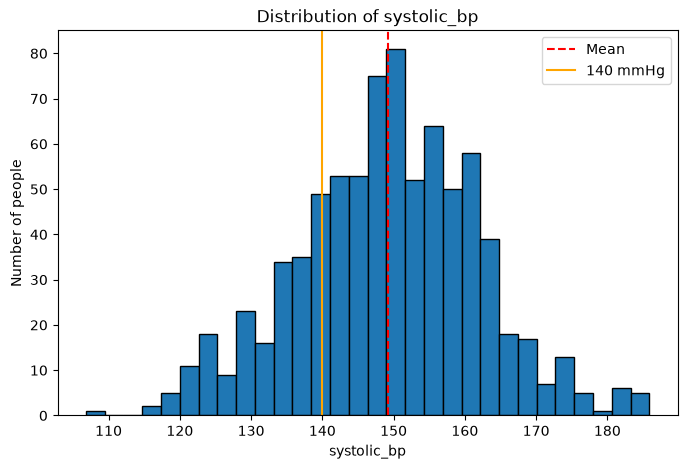

In [4]:
# The class draws the histogram, and I add the 140 mmHg line here
ax = analyzer.plot_histogram("systolic_bp")
ax.axvline(140, color="orange", label="140 mmHg")
ax.legend()
plt.show()

**Comment:** The class gives the same normal CI as the functions.
The bootstrap CI is a little different, because it is a new random
sample, but the difference is very small. With one method I can draw
a histogram of any column, and I can still add extra lines in the
notebook because the method returns the axes.

## 3. Linear regression: blood pressure and age
In Part 1 I thought that age may be important for blood pressure.
Now I test this with a linear regression:

blood pressure = b0 + b1 × age

I write the data as a matrix equation y = Xb, where X has a column of
ones (for b0) and a column with age. Then I use least squares
(`np.linalg.lstsq`) to find the b that makes the squared errors as small
as possible.

In [5]:
coef, r2 = analyzer.regression("systolic_bp", ["age"])
b0, b1 = coef

print(f"Intercept (b0): {b0:.1f} mmHg")
print(f"Slope (b1):     {b1:.3f} mmHg per year")
print(f"R²:             {r2:.3f}")

# Check: for one variable, R² should be the same as the correlation squared
corr = np.corrcoef(df["age"], df["systolic_bp"])[0, 1]
print(f"Correlation²:   {corr ** 2:.3f}")

Intercept (b0): 122.7 mmHg
Slope (b1):     0.536 mmHg per year
R²:             0.369
Correlation²:   0.369


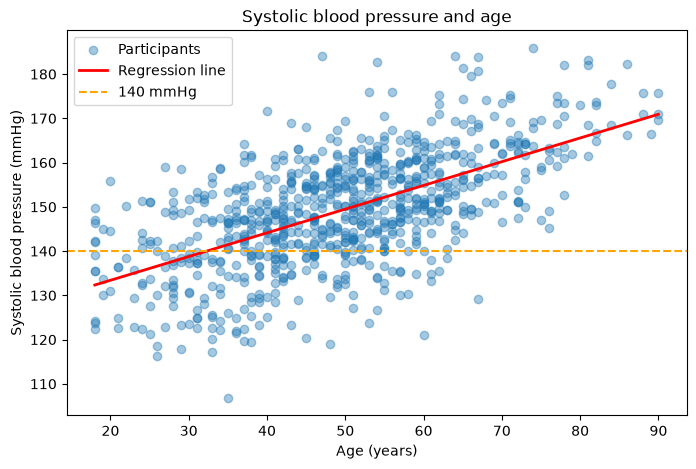

In [6]:
# Points for the regression line, from the youngest to the oldest person
age_line = np.linspace(df["age"].min(), df["age"].max(), 100)
bp_line = predict(age_line, coef)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["age"], df["systolic_bp"], alpha=0.4, label="Participants")
ax.plot(age_line, bp_line, color="red", linewidth=2, label="Regression line")
ax.axhline(140, color="orange", linestyle="--", label="140 mmHg")

ax.set_title("Systolic blood pressure and age")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Systolic blood pressure (mmHg)")
ax.legend()
plt.show()

**Comment:**
- The slope is 0.54 mmHg per year. This means that blood pressure is
  about 5.4 mmHg higher for every 10 years of age.
- R² = 0.37, so age alone explains about 37% of the variation in
  blood pressure. The rest depends on other things.
- For one variable, R² is the same as the correlation squared (0.369),
  so the regression code works correctly.
- The intercept (122.7 mmHg) is the predicted value at age 0. This is
  outside the data (the youngest person is 18), so it has no real meaning.

Compared with Part 1, where smokers had only 0.47 mmHg higher blood
pressure, the effect of age is much larger: 10 years of age gives about
11 times more difference than smoking.

## 4. Multiple regression

Age alone explained about 37% of the variation in blood pressure. Here I add more
variables to the same model: weight, cholesterol, sex and smoking. Each coefficient
now shows the effect of one variable when the others are held constant.

`sex` and `smoker` are text, so first I turn them into 0/1 columns
(`male` = 1 for men, `smoker_yes` = 1 for smokers).

In [7]:
# the matrix can only hold numbers, so text columns become 0/1
df["male"] = (df["sex"] == "M").astype(int)
df["smoker_yes"] = (df["smoker"] == "Yes").astype(int)

features = ["age", "weight", "cholesterol", "male", "smoker_yes"]
coef_multi, r2_multi = analyzer.regression("systolic_bp", features)

# put the coefficients in a small table so they are easier to read
coef_table = pd.DataFrame({
    "variable": ["intercept"] + features,
    "coefficient": coef_multi.round(3),
})
print(coef_table)

# compare with the model that only uses age
_, r2_age = analyzer.regression("systolic_bp", ["age"])
print(f"\nR² age only:     {r2_age:.3f}")
print(f"R² all features: {r2_multi:.3f}")

# coefficients have different units, so look at the effect of one std change
for col in ["age", "weight", "cholesterol"]:
    i = features.index(col) + 1   # +1 because index 0 is the intercept
    effect = coef_multi[i] * df[col].std()
    print(f"1 std of {col}: {effect:.1f} mmHg")

      variable  coefficient
0    intercept      108.859
1          age        0.527
2       weight        0.162
3  cholesterol        0.454
4         male        0.504
5   smoker_yes       -0.328

R² age only:     0.369
R² all features: 0.406
1 std of age: 7.6 mmHg
1 std of weight: 2.2 mmHg
1 std of cholesterol: 0.4 mmHg


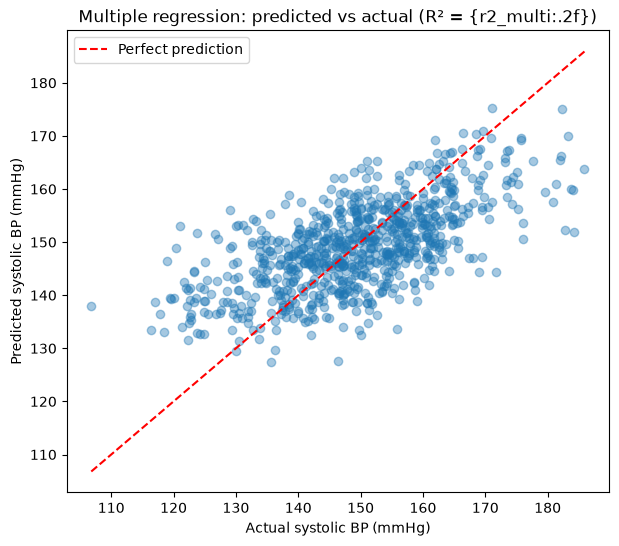

In [8]:
X_multi = df[features].to_numpy()
y_pred = predict(X_multi, coef_multi)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df["systolic_bp"], y_pred, alpha=0.4)

# if the model was perfect, every dot would sit on this line
low, high = df["systolic_bp"].min(), df["systolic_bp"].max()
ax.plot([low, high], [low, high], color="red", linestyle="--", label="Perfect prediction")

ax.set_xlabel("Actual systolic BP (mmHg)")
ax.set_ylabel("Predicted systolic BP (mmHg)")
ax.set_title("Multiple regression: predicted vs actual (R² = {r2_multi:.2f})")
ax.legend()
plt.show()

**Interpretation**

- **Age is still the main factor.** Its coefficient barely changes (0.54 → 0.53),
  so the age effect is not explained by weight or cholesterol. One standard
  deviation in age (about 14.5 years) means about 7.6 mmHg higher blood pressure.
- **Weight** adds a little: about 1.6 mmHg per 10 kg, or 2.2 mmHg per standard deviation.
- **Cholesterol and sex** have very small effects (under 1 mmHg).
- **Smoking** has a coefficient of about −0.3 mmHg. When age and the other variables
  are held constant, smokers do not have higher blood pressure. This agrees with the
  t-test and permutation test in Part 1, now with a different method.
- R² only goes from 0.37 to 0.41, so the four extra variables add little. About 60%
  of the variation is still unexplained, and the plot shows the model cannot predict
  very high or very low values.

**Limitations:** The coefficients have no p-values or confidence intervals here, so I
do not claim which small effects are real. The intercept (108.9) is for age 0 and
weight 0, which is outside the data, so it has no real meaning. And this is
correlation, not causation.

## 5. More analyses with the class

The class can now also compare groups. Here I use it to look at two things
Part 1 did not cover: how blood pressure changes between age groups, and
which groups have a higher disease rate.

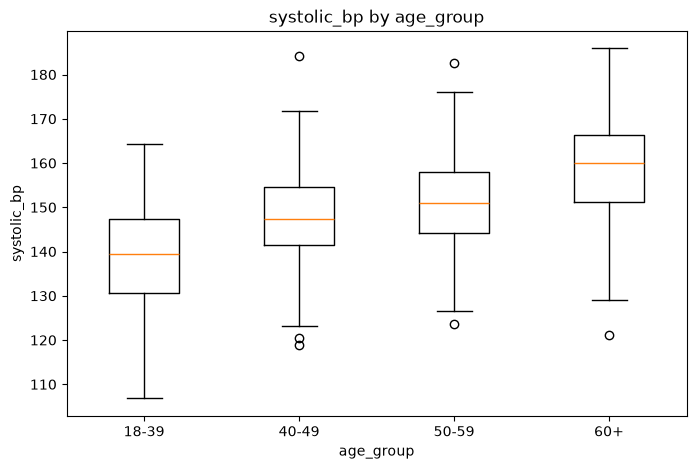

In [9]:
# split age into 4 groups, so it can be used like sex or smoker
df["age_group"] = pd.cut(df["age"], bins=[0, 39, 49, 59, 100],
                         labels=["18-39", "40-49", "50-59", "60+"])
analyzer.plot_boxplot("systolic_bp", "age_group")
plt.show()

In [10]:
print(analyzer.disease_rate_by("sex").round(1))
print(analyzer.disease_rate_by("smoker").round(1))
print(analyzer.disease_rate_by("age_group").round(1))

sex
F    4.5
M    7.3
Name: disease, dtype: float64
smoker
No     4.8
Yes    8.9
Name: disease, dtype: float64
age_group
18-39    4.4
40-49    6.8
50-59    7.0
60+      5.3
Name: disease, dtype: float64
